<a href="https://colab.research.google.com/github/thenmozhinn-er/DermaLens-AI/blob/main/DermaLens_Ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install torch torchvision safetensors huggingface_hub pillow matplotlib

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from PIL import Image
import matplotlib.pyplot as plt

print("DermaLens AI setup started!")
print("PyTorch version:", torch.__version__)

DermaLens AI setup started!
PyTorch version: 2.11.0+cpu


In [ ]:
weights_path = hf_hub_download(
    repo_id="adeIaide/skin-lesion-7class-efficientnet",
    filename="model.safetensors"
)

print("Model weights downloaded successfully!")
print(weights_path)

model.safetensors: reconstructing file:   0%|          |  0.00B / 16.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model weights downloaded successfully!
/root/.cache/huggingface/hub/models--adeIaide--skin-lesion-7class-efficientnet/snapshots/b5ebe73c3b89baa90ee4f991afa318385414a973/model.safetensors


In [ ]:
from huggingface_hub import hf_hub_download
import json

config_path = hf_hub_download(
    repo_id="adeIaide/skin-lesion-7class-efficientnet",
    filename="config.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

print(config)

config.json:   0%|          | 0.00/959 [00:00<?, ?B/s]

{'architecture': 'EfficientNetB0', 'backbone': 'efficientnet_b0', 'num_classes': 7, 'image_size': 320, 'input_mode': 'RGB', 'dropout': 0.3, 'pretrained_backbone': 'ImageNet', 'class_names': ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC'], 'class_to_index': {'MEL': 0, 'NV': 1, 'BCC': 2, 'AKIEC': 3, 'BKL': 4, 'DF': 5, 'VASC': 6}, 'normalization': {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}, 'training': {'seed': 42, 'best_epoch': 17, 'epochs': 20, 'optimizer': 'AdamW', 'learning_rate': 0.0002, 'weight_decay': 0.0001, 'label_smoothing': 0.05}, 'evaluation': {'split': 'internal lesion-disjoint development split', 'num_images': 2026, 'macro_f1': 0.76409086453313, 'balanced_accuracy': 0.7958152647156634, 'accuracy': 0.8637709772951628, 'macro_auroc': 0.9342744710338876}}


In [ ]:
with open(example_path, "r") as f:
    code = f.read()

print(code[:5000])

"""Standalone inference example for adeIaide/skin-lesion-7class-efficientnet."""

from __future__ import annotations

import argparse
import json
from pathlib import Path

import torch
from huggingface_hub import hf_hub_download
from PIL import Image
from safetensors.torch import load_file
from torch import nn
from torchvision import models, transforms


REPO_ID = "adeIaide/skin-lesion-7class-efficientnet"


class EfficientNetB0(nn.Module):
    def __init__(self, num_classes: int = 7, dropout: float = 0.3) -> None:
        super().__init__()
        network = models.efficientnet_b0(weights=None)
        embedding_dim = network.classifier[1].in_features
        self.encoder = nn.Sequential(network.features, network.avgpool, nn.Flatten(1))
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.dropout(self.encoder(image)))


def load_model(d

In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
import json
from pathlib import Path

# Download the model configuration and trained weights
repo_id = "adeIaide/skin-lesion-7class-efficientnet"

config_path = hf_hub_download(repo_id=repo_id, filename="config.json")
weights_path = hf_hub_download(repo_id=repo_id, filename="model.safetensors")

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

# Recreate the official model architecture
class EfficientNetB0(nn.Module):
    def __init__(self, num_classes=7, dropout=0.3):
        super().__init__()

        network = models.efficientnet_b0(weights=None)
        embedding_dim = network.classifier[1].in_features

        self.encoder = nn.Sequential(
            network.features,
            network.avgpool,
            nn.Flatten(1)
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, image):
        return self.classifier(self.dropout(self.encoder(image)))

# Load the trained parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EfficientNetB0(
    num_classes=int(config["num_classes"]),
    dropout=float(config["dropout"])
)

model.load_state_dict(load_file(weights_path, device=str(device)))
model = model.to(device).eval()

print("✅ Model loaded successfully!")
print("Device:", device)
print("Number of classes:", config["num_classes"])
print("Class names:", config["class_names"])

✅ Model loaded successfully!
Device: cpu
Number of classes: 7
Class names: ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']


In [ ]:
from torchvision import transforms
from PIL import Image

# Prepare the image in the format expected by the model
norm = config["normalization"]

transform = transforms.Compose([
    transforms.Resize((config["image_size"], config["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(norm["mean"], norm["std"])
])

def predict_image(image_path):
    image = Image.open(image_path).convert("RGB")
    batch = transform(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        outputs = model(batch)
        scores = torch.softmax(outputs, dim=1)[0].cpu().tolist()

    return dict(zip(config["class_names"], scores))

print("✅ Image prediction function is ready!")

✅ Image prediction function is ready!


In [ ]:
for root, dirs, files_list in os.walk("extracted_images"):
    for name in files_list[:10]:
        print(os.path.join(root, name))
    break

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Close-Up Dermatoscopic Mole on Skin.png to Close-Up Dermatoscopic Mole on Skin.png


In [ ]:
from pathlib import Path

image_path = next(iter(uploaded.keys()))

if Path(image_path).suffix.lower() not in [".jpg", ".jpeg", ".png"]:
    print("Please upload one JPG or PNG image, not a ZIP file.")
else:
    results = predict_image(image_path)

    for label, score in sorted(
        results.items(),
        key=lambda item: item[1],
        reverse=True
    ):
        print(f"{label}: {score * 100:.2f}%")

MEL: 43.86%
NV: 18.45%
DF: 13.55%
VASC: 11.92%
AKIEC: 6.34%
BCC: 5.05%
BKL: 0.82%


In [ ]:
image_path = next(iter(uploaded.keys()))
results = predict_image(image_path)

for label, score in sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{label}: {score * 100:.2f}%")

MEL: 43.86%
NV: 18.45%
DF: 13.55%
VASC: 11.92%
AKIEC: 6.34%
BCC: 5.05%
BKL: 0.82%


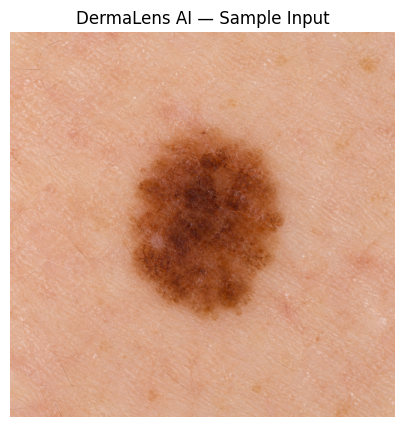

Top model output: MEL
Model score: 43.86%


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(5, 5))
plt.imshow(Image.open(image_path).convert("RGB"))
plt.axis("off")
plt.title("DermaLens AI — Sample Input")
plt.show()

top_label = max(results, key=results.get)

print("Top model output:", top_label)
print(f"Model score: {results[top_label] * 100:.2f}%")

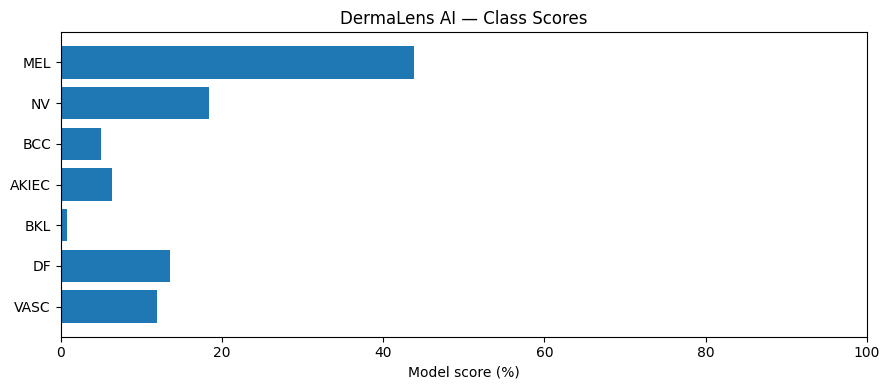

In [ ]:
labels = list(results.keys())
scores = [results[label] * 100 for label in labels]

plt.figure(figsize=(9, 4))
plt.barh(labels, scores)
plt.xlabel("Model score (%)")
plt.title("DermaLens AI — Class Scores")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

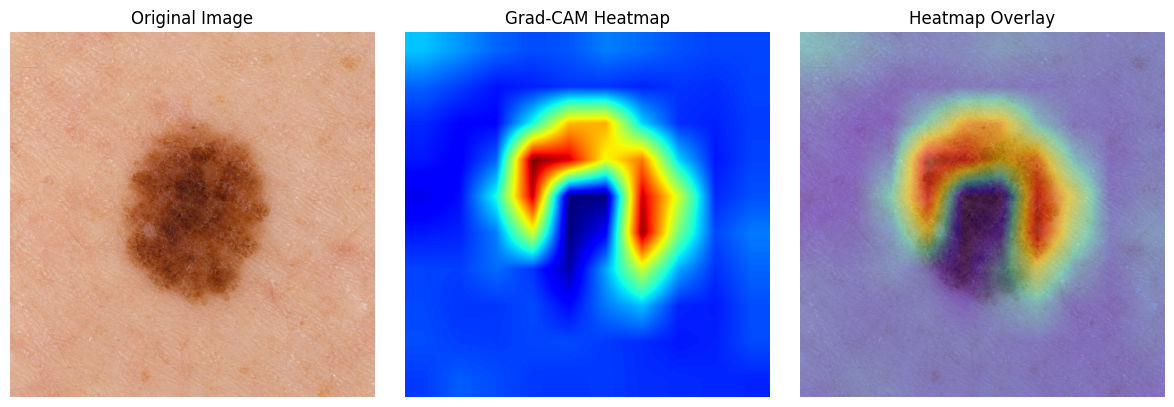

Predicted class: MEL


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Select the final convolutional layer
target_layer = model.encoder[0][-1]

activations = None
gradients = None

def save_activation(module, inputs, output):
    global activations
    activations = output

def save_gradient(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

handle1 = target_layer.register_forward_hook(save_activation)
handle2 = target_layer.register_full_backward_hook(save_gradient)

# Prepare the image
image = Image.open(image_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0).to(device)

model.zero_grad()
output = model(input_tensor)
predicted_class = output.argmax(dim=1).item()
output[0, predicted_class].backward()

# Calculate Grad-CAM
weights = gradients.mean(dim=(2, 3), keepdim=True)
cam = (weights * activations).sum(dim=1, keepdim=True)
cam = F.relu(cam)
cam = F.interpolate(
    cam,
    size=image.size[::-1],
    mode="bilinear",
    align_corners=False
)

cam = cam[0, 0].detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Display the image and heatmap
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Heatmap Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Predicted class:", config["class_names"][predicted_class])

handle1.remove()
handle2.remove()

In [ ]:
!pip -q install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 94.9 MB/s eta 0:00:00


In [ ]:
%%writefile app.py
import streamlit as st

st.set_page_config(
    page_title="DermaLens AI",
    page_icon="🔬",
    layout="wide"
)

st.title("🔬 DermaLens AI")
st.subheader("See beyond the surface")

st.write(
    "An educational prototype exploring AI-based "
    "skin lesion image analysis and explainability."
)

st.warning(
    "Research and educational use only. "
    "This tool is not a medical diagnostic system. "
    "Do not use its output to make healthcare decisions."
)

uploaded_file = st.file_uploader(
    "Upload a dermoscopic image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    st.image(
        uploaded_file,
        caption="Uploaded sample image",
        width=400
    )

    st.info(
        "Image uploaded successfully. "
        "Model inference and Grad-CAM integration are the next steps."
    )

Writing app.py


In [ ]:
import os

print("App file exists:", os.path.exists("app.py"))

App file exists: True


In [ ]:
print("Model loaded:", model is not None)
print("Device:", device)
print("Image size:", config["image_size"])
print("Classes:", config["class_names"])
print("Grad-CAM function:", "gradcam" in globals())

Model loaded: True
Device: cpu
Image size: 320
Classes: ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']
Grad-CAM function: False


In [ ]:

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image

def generate_gradcam(image_path):
    global activations, gradients

    image = Image.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    model.zero_grad()
    output = model(input_tensor)
    predicted_class = output.argmax(dim=1).item()
    output[0, predicted_class].backward()

    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = (weights * activations).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=image.size[::-1],
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    scores = torch.softmax(output.detach(), dim=1)[0].cpu().tolist()
    results = dict(zip(config["class_names"], scores))

    return image, cam, results


In [ ]:
import os

for root, dirs, files_list in os.walk("extracted_images"):
    for name in files_list[:10]:
        print(os.path.join(root, name))

extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0000141_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0011155_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0010592_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0010587_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0000299_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0011168_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0011175_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0000213_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0008659_Segmentation.png
extracted_images/ISBI2016_ISIC_Part1_Test_GroundTruth/ISIC_0000197_Segmentation.png


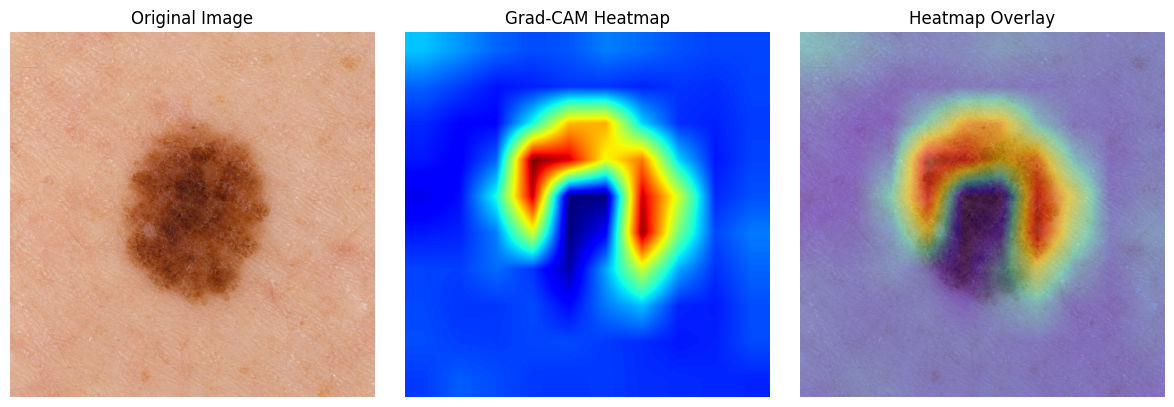

Prediction scores: {'MEL': 0.438612699508667, 'NV': 0.18454143404960632, 'BCC': 0.050538912415504456, 'AKIEC': 0.06343620270490646, 'BKL': 0.008216410875320435, 'DF': 0.13545061647891998, 'VASC': 0.11920376121997833}


In [ ]:

# Register hooks for the Grad-CAM calculation
target_layer = model.encoder[0][-1]

handle1 = target_layer.register_forward_hook(save_activation)
handle2 = target_layer.register_full_backward_hook(save_gradient)

image, cam, results = generate_gradcam(image_path)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(cam, cmap="jet", alpha=0.4)
plt.title("Heatmap Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction scores:", results)

handle1.remove()
handle2.remove()


In [ ]:

!pip -q install fastapi uvicorn python-multipart nest-asyncio
print("FastAPI setup complete!")


FastAPI setup complete!


In [ ]:

import io
import base64
import nest_asyncio
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI(title="DermaLens AI API")

# Development configuration only.
# Restrict allowed origins before public deployment.
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_methods=["POST", "GET"],
    allow_headers=["*"],
)

# Store feature maps and gradients for Grad-CAM.
cam_state = {}

def capture_activations(module, inputs, output):
    cam_state["activations"] = output

def capture_gradients(module, grad_input, grad_output):
    cam_state["gradients"] = grad_output[0]

# Register hooks once for the API.
target_layer = model.encoder[0][-1]
forward_handle = target_layer.register_forward_hook(capture_activations)
backward_handle = target_layer.register_full_backward_hook(capture_gradients)

@app.get("/")
def health_check():
    return {"status": "DermaLens AI API is running"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    if file.content_type not in ["image/jpeg", "image/png", "image/webp"]:
        raise HTTPException(
            status_code=400,
            detail="Upload a JPG, PNG, or WebP image."
        )

    raw_bytes = await file.read()

    if len(raw_bytes) > 8 * 1024 * 1024:
        raise HTTPException(status_code=413, detail="Image must be under 8 MB.")

    try:
        image = Image.open(io.BytesIO(raw_bytes)).convert("RGB")
    except Exception:
        raise HTTPException(status_code=400, detail="Invalid image file.")

    input_tensor = transform(image).unsqueeze(0).to(device)

    try:
        model.zero_grad(set_to_none=True)
        cam_state.clear()

        output = model(input_tensor)
        predicted_index = output.argmax(dim=1).item()
        output[0, predicted_index].backward()

        activations = cam_state["activations"]
        gradients = cam_state["gradients"]

        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam,
            size=(image.height, image.width),
            mode="bilinear",
            align_corners=False
        )[0, 0].detach().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        scores = torch.softmax(output.detach(), dim=1)[0].cpu().tolist()
        results = {
            name: round(float(score), 6)
            for name, score in zip(config["class_names"], scores)
        }

        # Encode the heatmap as PNG for the frontend.
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(image)
        ax.imshow(cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)
        ax.axis("off")

        buffer = io.BytesIO()
        fig.savefig(
            buffer, format="png", bbox_inches="tight",
            pad_inches=0, dpi=120
        )
        plt.close(fig)
        buffer.seek(0)

        heatmap_base64 = base64.b64encode(
            buffer.getvalue()
        ).decode("utf-8")

        return {
            "model_classes": config["class_names"],
            "scores": results,
            "top_class": config["class_names"][predicted_index],
            "heatmap": "data:image/png;base64," + heatmap_base64,
            "notice": (
                "Research and educational prototype only. "
                "Not for diagnosis or treatment decisions."
            )
        }

    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail=f"Inference failed: {str(exc)}"
        )

print("API endpoints created: / and /predict")


API endpoints created: / and /predict


In [ ]:

import nest_asyncio
import uvicorn
import threading
import time

nest_asyncio.apply()

def run_api():
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="info")

api_thread = threading.Thread(target=run_api, daemon=True)
api_thread.start()

time.sleep(2)
print("API server startup requested.")


INFO:     Started server process [876]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


API server startup requested.


In [ ]:
!pip -q install pyngrok

In [ ]:
from getpass import getpass
from pyngrok import ngrok

token = getpass("Enter your ngrok auth token: ")
ngrok.set_auth_token(token)

Enter your ngrok auth token: ··········


In [ ]:
tunnel = ngrok.connect(8000, "http")
public_url = tunnel.public_url

print("DermaLens API URL:", public_url)
print("API documentation:", public_url + "/docs")

ERROR:pyngrok.process.ngrok:t=2026-10-20T07:28:42+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-20T07:28:42+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n.

In [ ]:
!pip -q install --upgrade pyngrok

from getpass import getpass
from pyngrok import ngrok

token = getpass("Paste your correct ngrok authtoken: ").strip()
ngrok.set_auth_token(token)

print("Token configured.")

Paste your correct ngrok authtoken: ··········
Token configured.


In [ ]:
tunnel = ngrok.connect(8000, "http")

public_url = tunnel.public_url

print("DermaLens API URL:", public_url)
print("API documentation:", public_url + "/docs")

DermaLens API URL: https://unsterile-expletive-playback.ngrok-free.dev
API documentation: https://unsterile-expletive-playback.ngrok-free.dev/docs


In [ ]:
torch.save(
    model.state_dict(),
    "/content/dermalens_model.pth"
)

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("Model variable exists:", "model" in globals())

if "model" in globals():
    print("Model type:", type(model))

PyTorch version: 2.11.0+cpu
Model variable exists: True
Model type: <class '__main__.EfficientNetB0'>


In [ ]:
import torch

print("Model type:", type(model))
print("Is a PyTorch model:", isinstance(model, torch.nn.Module))

if isinstance(model, torch.nn.Module):
    print("\nModel architecture:")
    print(model)

    print("\nFirst few parameter shapes:")
    for name, param in list(model.named_parameters())[:5]:
        print(name, param.shape)

Model type: <class '__main__.EfficientNetB0'>
Is a PyTorch model: True

Model architecture:
EfficientNetB0(
  (encoder): Sequential(
    (0): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1)

In [ ]:
import torch

model.eval()

torch.save(
    model.state_dict(),
    "/content/dermalens_model.pth"
)

print("Model weights saved successfully!")

Model weights saved successfully!


In [ ]:
from google.colab import files

files.download("/content/dermalens_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(json.dumps(config, indent=2))

{
  "architecture": "EfficientNetB0",
  "backbone": "efficientnet_b0",
  "num_classes": 7,
  "image_size": 320,
  "input_mode": "RGB",
  "dropout": 0.3,
  "pretrained_backbone": "ImageNet",
  "class_names": [
    "MEL",
    "NV",
    "BCC",
    "AKIEC",
    "BKL",
    "DF",
    "VASC"
  ],
  "class_to_index": {
    "MEL": 0,
    "NV": 1,
    "BCC": 2,
    "AKIEC": 3,
    "BKL": 4,
    "DF": 5,
    "VASC": 6
  },
  "normalization": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  },
  "training": {
    "seed": 42,
    "best_epoch": 17,
    "epochs": 20,
    "optimizer": "AdamW",
    "learning_rate": 0.0002,
    "weight_decay": 0.0001,
    "label_smoothing": 0.05
  },
  "evaluation": {
    "split": "internal lesion-disjoint development split",
    "num_images": 2026,
    "macro_f1": 0.76409086453313,
    "balanced_accuracy": 0.7958152647156634,
    "accuracy": 0.8637709772951628,
    "macro_auroc": 0.9342744710338876


In [ ]:

from google.colab import files
from PIL import Image
from torchvision import transforms
import torch

# Upload a test image
uploaded = files.upload()
filename = next(iter(uploaded))

# Use the exact preprocessing from your config
preprocess = transforms.Compose([
    transforms.Resize(
        (config["image_size"], config["image_size"])
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=config["normalization"]["mean"],
        std=config["normalization"]["std"]
    )
])

image = Image.open(filename).convert("RGB")
input_tensor = preprocess(image).unsqueeze(0).to(device)

# Run inference
model.eval()
with torch.no_grad():
    logits = model(input_tensor)
    scores = torch.softmax(logits, dim=1)[0]

# Display all seven output scores
class_names = config["class_names"]
ranked = sorted(
    zip(class_names, scores.cpu().tolist()),
    key=lambda item: item[1],
    reverse=True
)

print("Model output:")
for label, score in ranked:
    print(f"{label}: {score * 100:.2f}%")

print("\nHighest-scoring class:", ranked[0][0])
print("Output score:", f"{ranked[0][1] * 100:.2f}%")


Saving Close-Up Dermatoscopic Mole on Skin.png to Close-Up Dermatoscopic Mole on Skin (1).png
Model output:
MEL: 43.86%
NV: 18.45%
DF: 13.55%
VASC: 11.92%
AKIEC: 6.34%
BCC: 5.05%
BKL: 0.82%

Highest-scoring class: MEL
Output score: 43.86%
